# Exploratory Data Analysis — BPI Challenge 2015, Municipality 1

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

This notebook explores the event log, checks its quality, documents the decisions used for modelling and saves the
processed data for `02_modelling.ipynb`.

## 1. TL;DR

The data is a public event log of **52,217 recorded steps** in **1,199 building-permit cases** from one Dutch
municipality (October 2010 – July 2015). For the 956 cases with a recorded end date, the time from the first to the last
recorded step (the *recorded activity span*) varies enormously: the median is 63 days, but some cases run for years. Every
case leaves a trail of recorded steps from its very first day, so it is worth testing whether the early steps already say
something about which cases will run long.

## 2. Introduction & motivation

Public administrations handle many cases, for example applications for a building permit. Each case goes through steps
such as registration, review and a decision. In this dataset, some cases have recorded activity spans of only a few weeks, others of many months. If the cases
likely to run long could be recognised **early**, while they are still being handled, someone could look at them sooner.

**Research question:** *Can early information from an administrative process help identify cases likely to have a longer
recorded activity span?*

This notebook prepares the ground: it describes the data, checks its quality and defines what "long" means. The models
are in `02_modelling.ipynb`.

**Motivation:** the idea comes from SPAR, where the same question could later be asked about its own historical cases.
This dataset is **not** SPAR data and contains no records from Montenegro; it is a public research dataset from one Dutch
municipality. Any use for SPAR would be future research.

## 3. Data provenance

| Item | Information |
|---|---|
| Dataset | **BPI Challenge 2015 Municipality 1**, version 1 |
| Creator | Boudewijn van Dongen |
| Publisher | Eindhoven University of Technology, via **4TU.ResearchData** (issued 2015-05-01) |
| DOI | [10.4121/uuid:a0addfda-2044-4541-a450-fdcc9fe16d17](https://doi.org/10.4121/uuid:a0addfda-2044-4541-a450-fdcc9fe16d17) |
| Citation | van Dongen, Boudewijn (2015): BPI Challenge 2015 Municipality 1. Version 1. 4TU.ResearchData. dataset. https://doi.org/10.4121/uuid:a0addfda-2044-4541-a450-fdcc9fe16d17 |
| Content | Building-permit applications of one Dutch municipality, as an XES event log |
| Period | The source describes "a period of approximately four years". The events **observed in the file** run from October 2010 to July 2015 (section 6). |
| File | `data/raw/BPIC15_1.xes`, 41,227,060 bytes, SHA-256 `7591f70d4a4d536ead76a56c2fa493fbe22bf2ec7e06c8ddd29da79bd666e516` (the MD5 matches the value published by 4TU) |
| Terms | [4TU General Terms of Use](https://doi.org/10.4121/resource:terms_of_use): the dataset must be cited as above |

**Permission to use:** the dataset is public for research use under the 4TU General Terms of Use, which require citation.
These terms do **not** name a Creative Commons licence, and permission to redistribute processed copies has not been
explicitly established. The processed file made in section 12 therefore stays on the local computer and is re-created
by this notebook.

The original file is kept **unchanged**: it is stored with Git LFS (see `data/README.md`) and only read here. It contains
resource identifiers (numbers), not employee names.

## 4. Data dictionary

The event log has **29 columns**. Columns starting with `case:` describe the whole case, so their value repeats on every
event of that case. Where the source does not document a column, the meaning is marked as an inference or as not
documented; I do not guess beyond that. (The same information, with missing percentages and value counts, is in
`data/data_dictionary.csv` and in the appendix.)

| Column | Meaning | Units / values |
|---|---|---|
| `question` | Exact source-system meaning is not fully documented; values look like answers recorded with a step, e.g. True/False or a number (inference). | Text; 422 different values (e.g. True/False or numbers); the text `EMPTY` marks a missing answer |
| `dateFinished` | Exact meaning not fully documented; likely the date the step was finished (inference). | Text in the form `YYYY-MM-DD HH:MM:SS` (not converted to a date) |
| `dueDate` | Exact meaning not fully documented; likely the deadline of the step (inference). | Date and time (UTC); 93.6% missing |
| `action_code` | Activity code of the event. | Text code; equal to `concept:name` except 1 missing value |
| `activityNameEN` | English description of the activity. | Text; 289 different names |
| `planned` | Exact meaning not fully documented; likely the planned date of the step (inference). | Date and time (UTC); 11.5% missing |
| `time:timestamp` | When the event happened (XES standard timestamp). | Date and time (UTC); 45.9% of the events are at exactly local midnight, which suggests a date only (inference) |
| `monitoringResource` | A second resource ID per event. Exact source-system meaning is not fully documented; possibly the resource monitoring the step (inference). | Numeric ID stored as text; 26 values |
| `org:resource` | Resource that recorded/performed the event (XES standard resource). | Numeric ID stored as text; 23 values; no names |
| `activityNameNL` | Dutch description of the activity. | Text; 289 different names (Dutch) |
| `concept:name` | Activity code of the event (XES standard activity name), e.g. 01_HOOFD_010. | Text code such as `01_HOOFD_010`; 398 codes |
| `lifecycle:transition` | Lifecycle state of the event (XES standard). | Text; always `complete` |
| `case:endDate` | Recorded end date of the case. Exact meaning is not fully documented; it often differs from the last recorded event (see section 7.5). | Date and time (UTC); missing for 243 of 1,199 cases |
| `case:caseStatus` | Status code of the case. | Text code `G`, `O` or `T` (meaning not documented) |
| `case:SUMleges` | Total fee of the application ('leges' is Dutch for fees) (inference from the name). | Number (fee amount; currency not stated); 16.5% missing |
| `case:last_phase` | Last phase the case reached, as a Dutch label (e.g. 'Beschikking verzonden' ≈ 'decision sent'). | Dutch text label; 27 values |
| `case:case_type` | Type of case. | Text; one value (`557669`) for every case |
| `case:concept:name` | Case ID: identifies the permit application the event belongs to. | Numeric ID stored as text; 1,199 cases |
| `case:Responsible_actor` | Exact meaning not fully documented; likely the responsible person/unit (inference). | Numeric ID stored as text; 20 values |
| `case:parts` | Permit components requested, comma-separated Dutch labels (e.g. 'Bouw' ≈ building). | Comma-separated Dutch labels; 88 combinations |
| `case:termName` | Name of a legal time limit linked to the case (Dutch label, e.g. 'Termijn bezwaar en beroep'). | Dutch text label; 13 values; 26.3% missing |
| `case:endDatePlanned` | Exact meaning not fully documented; likely a planned end date (inference). | Date and time (UTC); 86.4% missing |
| `case:startDate` | Start date of the case. | Date and time (UTC); usually equal to the first event (checked in section 7) |
| `case:requestComplete` | Whether the application (request) was complete, judging by the name (inference). | Text `TRUE` / `FALSE` |
| `case:IDofConceptCase` | ID of a related 'concept' case. Exact meaning is not fully documented. | ID stored as text; 31.4% missing |
| `case:landRegisterID` | Land-register (cadastral) ID, judging by the name (inference). | ID stored as text; 84.7% missing |
| `case:caseProcedure` | Type of permit procedure: 'Regulier' ≈ regular, 'Uitgebreid' ≈ extended. | Text `Regulier` (regular) or `Uitgebreid` (extended); 89.1% missing |
| `case:Includes_subCases` | Whether the case includes sub-cases: 'J' = ja (yes), 'N' = nee (no). | Text `J` (yes) / `N` (no); 21.6% missing |
| `dateStop` | Exact source-system meaning is not fully documented. | Text; only 2 of 52,217 rows have a value |

**Dates that are easy to confuse**

- `time:timestamp` is **when each step was recorded**. The **recorded activity span** of a case is the time between its
  first and its last `time:timestamp`.
- `case:endDate` is a **recorded end date** of the whole case. Its exact meaning is not documented, and it often differs
  from the last recorded step (section 7), so it is **not** treated as proof that the case was administratively finished.
- `case:startDate` is a recorded start date of the case (compared with the first step in section 7).
- `dateStop` is text with only two values; its meaning is not documented, so it is not used.
- None of these columns is a **legal deadline**. The recorded activity span is not a measure of delay, lateness or of
  anyone's performance.

## 5. Setup

**Import the packages.** PM4Py reads the XES event-log format; pandas and matplotlib are used for the analysis and the
charts. `hashlib` (part of Python) checks that the data file is the original. The warning filter hides only one optional
speed-up tip from PM4Py; all other warnings still show.

In [1]:
import hashlib
import os
import warnings
from pathlib import Path

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
# hide only PM4Py's optional speed-up tip ("Install the optional requirement `r4pm` ..."); other warnings still show
warnings.filterwarnings("ignore", message="Install the optional requirement `r4pm`")

import matplotlib.pyplot as plt
import pandas as pd
import pm4py



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

**Set the paths from the project folder.** This works whether Jupyter starts in the `notebooks` folder or in the project
folder, and it creates the folder for the saved charts.

In [2]:
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "raw" / "BPIC15_1.xes"
figures_folder = project_root / "docs" / "figures"
figures_folder.mkdir(parents=True, exist_ok=True)

print("Data file:", data_path.relative_to(project_root))

Data file: data\raw\BPIC15_1.xes


**Check that the data file is the original.** If the file is missing, or if it is only a small Git LFS pointer, the
checksum will not match and the notebook stops with a clear message.

In [3]:
expected_sha256 = "7591f70d4a4d536ead76a56c2fa493fbe22bf2ec7e06c8ddd29da79bd666e516"

if not data_path.exists():
    raise FileNotFoundError("data/raw/BPIC15_1.xes is missing. Run `git lfs pull` (see data/README.md).")

file_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
if file_sha256 != expected_sha256:
    raise ValueError("data/raw/BPIC15_1.xes is not the original file. Run `git lfs pull` (see data/README.md).")

print("File size:", data_path.stat().st_size, "bytes")
print("SHA-256 matches the original:", file_sha256 == expected_sha256)

File size: 41227060 bytes
SHA-256 matches the original: True


**Load the event log.** PM4Py reads the XES file and turns it into one pandas table (one row per recorded step). This
is the only data transformation in the notebook: no rows are removed and no values are changed.

In [4]:
log = pm4py.read_xes(str(data_path))
df = pm4py.convert_to_dataframe(log)

## 6. First look

**Size of the data.** Each row is one **recorded event** (one step, such as "send confirmation receipt"). A **case** is
one permit application; it consists of many events with the same `case:concept:name`.

In [5]:
print("Rows (events):", df.shape[0])
print("Columns:", df.shape[1])
print("Cases:", df["case:concept:name"].nunique())
print("Activity codes (concept:name):", df["concept:name"].nunique())
print("English activity names (activityNameEN):", df["activityNameEN"].nunique())
print("Resources (org:resource):", df["org:resource"].nunique())
print("First event:", df["time:timestamp"].min())
print("Last event:", df["time:timestamp"].max())

Rows (events): 52217
Columns: 29
Cases: 1199
Activity codes (concept:name): 398
English activity names (activityNameEN): 289
Resources (org:resource): 23
First event: 2010-10-04 22:00:00+00:00
Last event: 2015-07-31 22:00:00+00:00


The log has 52,217 events in 1,199 cases, observed from October 2010 to July 2015. There are more activity codes (398) than
English names (289) because some codes share the same description.

**Example rows.** The first steps of the first case show how one case is a sequence of events:

In [6]:
first_case = df["case:concept:name"].iloc[0]
first_case_events = df[df["case:concept:name"] == first_case]
first_case_events[["case:concept:name", "concept:name", "activityNameEN", "time:timestamp"]].head()

,case:concept:name,concept:name,activityNameEN,time:timestamp
0,10009138,01_HOOFD_010,register submission date request,2014-04-10 22:00:00+00:00
1,10009138,01_HOOFD_011,OLO messaging active,2014-04-13 22:00:00+00:00
2,10009138,01_HOOFD_020,send confirmation receipt,2014-04-13 22:00:00+00:00
3,10009138,02_DRZ_010,forward to the competent authority,2014-04-13 22:00:00+00:00
4,10009138,04_BPT_005,regular procedure without MER,2014-04-13 22:00:00+00:00


The case starts with "register submission date request", and several of the next steps have exactly the same timestamp
(22:00 UTC, which is midnight in the Netherlands). How often timestamps fall exactly at midnight is checked in section 7.

**Column names and data types.**

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52217 entries, 0 to 52216
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype              
---  ------                  --------------  -----              
 0   question                52217 non-null  str                
 1   dateFinished            52217 non-null  str                
 2   dueDate                 3340 non-null   datetime64[us, UTC]
 3   action_code             52216 non-null  str                
 4   activityNameEN          52217 non-null  str                
 5   planned                 46204 non-null  datetime64[us, UTC]
 6   time:timestamp          52217 non-null  datetime64[us, UTC]
 7   monitoringResource      52217 non-null  str                
 8   org:resource            52217 non-null  str                
 9   activityNameNL          52217 non-null  str                
 10  concept:name            52217 non-null  str                
 11  lifecycle:transition    52217 non-null  str         

Six columns are proper dates in UTC, one (`case:SUMleges`) is a number, and the other 22 are text, including all IDs. IDs
are labels, so text is the right type for them. `dateFinished` and `dateStop` look like dates but are stored as text;
they are not used, so they are left unchanged.

## 7. Data quality audit

### 7.1 Missing values

**Count the missing values in every column**, as a number and as a percentage of all events.

In [8]:
missing_count = df.isna().sum()
missing_count = missing_count[missing_count > 0]
missing_pct = missing_count / len(df) * 100

missing_table = pd.DataFrame({"missing_count": missing_count, "missing_pct": missing_pct.round(1)})
missing_table = missing_table.sort_values("missing_pct")
missing_table

,missing_count,missing_pct
action_code,1,0.0
case:Responsible_actor,19,0.0
case:parts,23,0.0
planned,6013,11.5
case:endDate,7744,14.8
case:SUMleges,8632,16.5
case:Includes_subCases,11280,21.6
case:termName,13743,26.3
case:IDofConceptCase,16381,31.4
case:landRegisterID,44210,84.7


**Chart of the missing percentages**, so the sparse columns stand out.

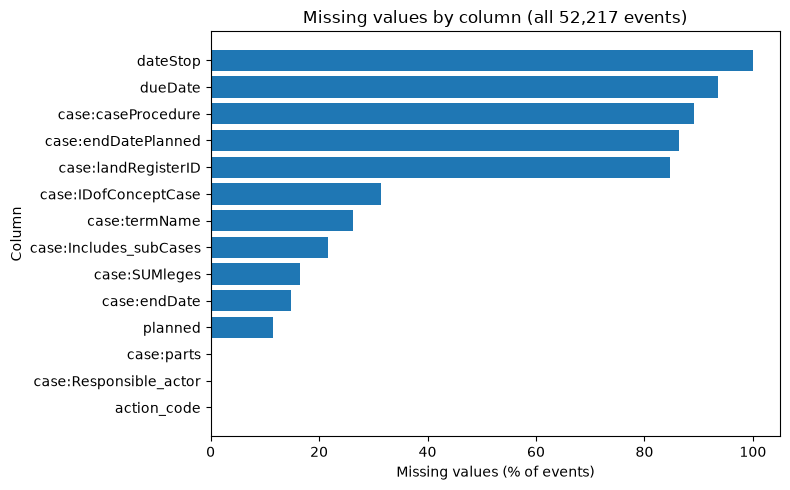

In [9]:
plt.figure(figsize=(8, 5))
plt.barh(missing_table.index, missing_table["missing_pct"])
plt.title("Missing values by column (all 52,217 events)")
plt.xlabel("Missing values (% of events)")
plt.ylabel("Column")
plt.tight_layout()
plt.savefig(figures_folder / "eda_missing_values.png", dpi=120)
plt.show()

14 of the 29 columns have missing values. Some optional columns are almost empty (`dateStop`, `dueDate`,
`case:caseProcedure`, `case:endDatePlanned`). `case:endDate` is missing for cases without a recorded end date (7.5).
`dateStop` shows 100.0% only because of rounding: 2 of its 52,217 values are filled in (section 7.2). A column with
missing values is not useless, so **nothing is removed and nothing is filled in**.

**Are the four key columns complete?** Case, activity, timestamp and resource are what the analysis depends on.

In [10]:
key_columns = ["case:concept:name", "concept:name", "time:timestamp", "org:resource"]
df[key_columns].isna().sum()

case:concept:name    0
concept:name         0
time:timestamp       0
org:resource         0
dtype: int64

The four key columns have no missing values, so every event can be placed in its case and in time.

### 7.2 Unusual values

**The two values in `dateStop`.** Only 2 of 52,217 rows have a value:

In [11]:
df.loc[df["dateStop"].notna(), ["case:concept:name", "concept:name", "dateStop"]]

,case:concept:name,concept:name,dateStop
25617,4517870,01_HOOFD_055,2012-04-03 10:48:53
25845,4557153,01_HOOFD_055,2012-04-17 12:35:24


Two isolated text values from April 2012, with no documented meaning, so `dateStop` is not used.

**The one missing activity code.** `action_code` normally repeats `concept:name`; one value is missing:

In [12]:
df.loc[df["action_code"].isna(), ["case:concept:name", "concept:name", "action_code", "activityNameEN"]]

,case:concept:name,concept:name,action_code,activityNameEN
26037,4565008,99_NOCODE_04,NaN,send letter receptive test not ok wait for rep...


The row is not repaired: `concept:name`, the activity column used in this project, is complete.

**Does `case:startDate` match the first recorded event?** First, one row per case with its first and last recorded event,
its recorded end date and its recorded start date (this table is also used below and in section 8):

In [13]:
case_summary = df.groupby("case:concept:name").agg(
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
    start_date=("case:startDate", "first"),
)

print("Cases:", len(case_summary))
print("Start date equal to the first event: ", (case_summary["start_date"] == case_summary["first_event"]).sum())
print("Start date after the first event:    ", (case_summary["start_date"] > case_summary["first_event"]).sum())
print("Start date before the first event:   ", (case_summary["start_date"] < case_summary["first_event"]).sum())

Cases: 1199
Start date equal to the first event:  1178
Start date after the first event:     19
Start date before the first event:    2


For 1,178 of the 1,199 cases the recorded start date equals the first recorded event; for 19 it is later and for 2 it
is earlier. The first recorded event is used as the start of a case, because it is defined the same way for every case.

### 7.3 Duplicates

In [14]:
full_duplicates = df.duplicated().sum()
repeated_events = df.duplicated(subset=["case:concept:name", "concept:name", "time:timestamp"]).sum()

print("Fully duplicated rows (all 29 columns equal):", full_duplicates)
print("Repeated case + activity + timestamp combinations:", repeated_events)

Fully duplicated rows (all 29 columns equal): 0
Repeated case + activity + timestamp combinations: 22


No row is a full copy of another. But 22 events repeat the **same activity in the same case at the same timestamp**;
each pair differs in another column (mostly `planned`, `dateFinished` or `question`), so they are separate recorded
events, not copies.
When many timestamps are recorded at midnight, a step done twice on the same day can look like this. They are kept.

### 7.4 Timestamp precision

**How many events are recorded exactly at local midnight?** Timestamps are stored in UTC. The Netherlands is one hour
ahead of UTC in winter and two hours in summer, so the timestamps are converted to Dutch local time first.

In [15]:
local_time = df["time:timestamp"].dt.tz_convert("Europe/Amsterdam")
at_midnight = (local_time.dt.hour == 0) & (local_time.dt.minute == 0) & (local_time.dt.second == 0)

print("Events recorded exactly at local midnight:", at_midnight.sum(), "of", len(df))
print(f"Share: {at_midnight.mean():.1%}")

Events recorded exactly at local midnight: 23990 of 52217
Share: 45.9%


**How many events share their timestamp with another event of the same case?**

In [16]:
events_per_timestamp = df.groupby(["case:concept:name", "time:timestamp"]).size()
tied_events = events_per_timestamp[events_per_timestamp > 1].sum()

print("Events sharing their timestamp with another event of the same case:", tied_events, "of", len(df))

Events sharing their timestamp with another event of the same case: 30433 of 52217


**Observed:** 45.9% of the events are recorded at exactly local midnight, and 30,433 events share a timestamp with
another event of the same case. **Inference:** many timestamps probably hold only a date, not a real time of day (the
source does not document this). So the true order of tied events is uncertain; the rows keep the order of the original
file. A cutoff such as "the first 30 days" can therefore be less precise than it looks for events close to the cutoff.

### 7.5 Recorded end dates and the analysis cohort

**How many cases have a recorded end date?** Only these cases form the analysis cohort (a recorded end date is not a verified
completion, see below); for the others, more events may have happened after the data was collected.

In [17]:
ended_cases = case_summary[case_summary["end_date"].notna()].copy()
excluded_cases = case_summary[case_summary["end_date"].isna()]

print("Cases with a recorded end date:", len(ended_cases))
print("Cases without a recorded end date:", len(excluded_cases))

Cases with a recorded end date: 956
Cases without a recorded end date: 243


**In which years did the cases without an end date start?**

In [18]:
cases_by_year = pd.DataFrame({
    "with end date": ended_cases["first_event"].dt.year.value_counts(),
    "without end date": excluded_cases["first_event"].dt.year.value_counts(),
}).sort_index()
cases_by_year.index.name = "year of first event"
cases_by_year

,with end date,without end date
year of first event,,
2010,56,23
2011,297,56
2012,268,36
2013,182,18
2014,146,89
2015,7,21


The cases without an end date are not spread evenly: 89 of the 243 started in **2014**, the second-to-last year of the
log. Many may simply still have been running when the data was collected. So the newest cases are under-represented
among the 956 cases, possibly especially the newer cases that take long.

**Does the recorded end date match the last recorded event?**

In [19]:
print("Last event AFTER the recorded end date: ", (ended_cases["last_event"] > ended_cases["end_date"]).sum())
print("Last event BEFORE the recorded end date:", (ended_cases["last_event"] < ended_cases["end_date"]).sum())
print("Last event ON the recorded end date:    ", (ended_cases["last_event"] == ended_cases["end_date"]).sum())

Last event AFTER the recorded end date:  713
Last event BEFORE the recorded end date: 170
Last event ON the recorded end date:     73


For most of the 956 cases (713) steps were still recorded **after** the recorded end date, for 170 the last step came
**before** it, and only 73 match. So `case:endDate` and the recorded activity span measure different things, and a recorded
end date is **not** an independently verified completion of the procedure. It is only used to select the cohort.

### 7.6 What I checked and what I changed

| | Result |
|---|---|
| Checked missing values | 14 columns have gaps; the 4 key columns are complete |
| Checked unusual values | `dateStop` (2 values), 1 missing `action_code`, start dates vs first events |
| Checked duplicates | 0 full duplicates; 22 repeated case/activity/timestamp events, kept |
| Checked timestamps | 45.9% at local midnight; 30,433 tied events |
| Checked end dates | 956 with, 243 without; often different from the last recorded event |
| **Removed rows or columns** | **No** |
| **Filled missing values** | **No** |
| **Changed the raw XES file** | **No** |

All 52,217 rows and 29 columns are kept, and the same table is exported in section 12.

## 8. Univariate exploration

### 8.1 Events per case

**Count the events of every case** and describe the counts.

In [20]:
events_per_case = df.groupby("case:concept:name").size()
events_per_case.describe()

count    1199.000000
mean       43.550459
std        16.988622
min         2.000000
25%        37.000000
50%        44.000000
75%        53.000000
max       101.000000
dtype: float64

**Histogram of the number of events per case.**

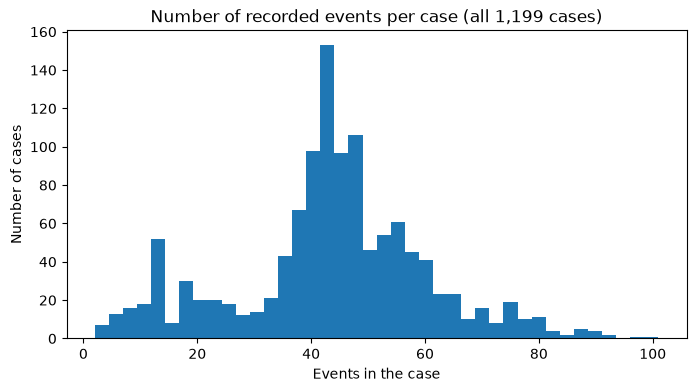

In [21]:
plt.figure(figsize=(8, 4))
plt.hist(events_per_case, bins=40)
plt.title("Number of recorded events per case (all 1,199 cases)")
plt.xlabel("Events in the case")
plt.ylabel("Number of cases")
plt.savefig(figures_folder / "eda_events_per_case.png", dpi=120)
plt.show()

A typical case has about 44 recorded events (median), but cases range from 2 to 101 events. Cases are therefore very
different in how much activity they produce.

### 8.2 Recorded activity span

**Calculate the recorded activity span** of every case with a recorded end date: the days between its first and its last
recorded event.

In [22]:
seconds_per_day = 24 * 60 * 60
ended_cases["duration_days"] = (ended_cases["last_event"] - ended_cases["first_event"]).dt.total_seconds() / seconds_per_day

ended_cases["duration_days"].describe()

count     956.000000
mean       98.127095
std       117.416488
min         1.433333
25%        47.422734
50%        63.000000
75%       102.533429
max      1486.000000
Name: duration_days, dtype: float64

**Histogram of the recorded activity span over its full range.**

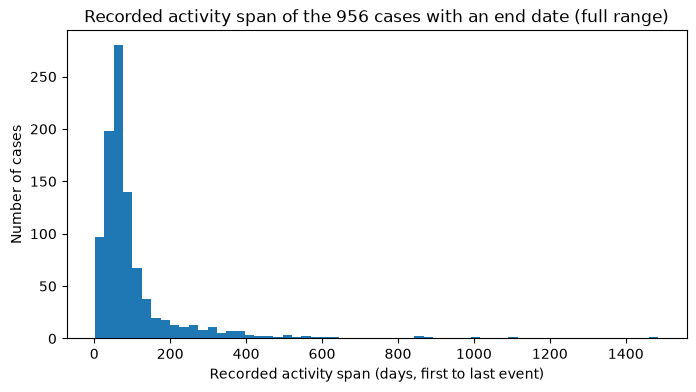

In [23]:
plt.figure(figsize=(8, 4))
plt.hist(ended_cases["duration_days"], bins=60)
plt.title("Recorded activity span of the 956 cases with an end date (full range)")
plt.xlabel("Recorded activity span (days, first to last event)")
plt.ylabel("Number of cases")
plt.savefig(figures_folder / "eda_recorded_span_full_range.png", dpi=120)
plt.show()

Most cases fall in the first few bars, and a long tail reaches 1,486 days. To see both the typical cases and the tail,
the next chart shows **the same 956 cases** on a logarithmic x-axis (1, 10, 100 and 1,000 days are equally far apart).
No cases are removed. The dashed line marks 63 days, the median.

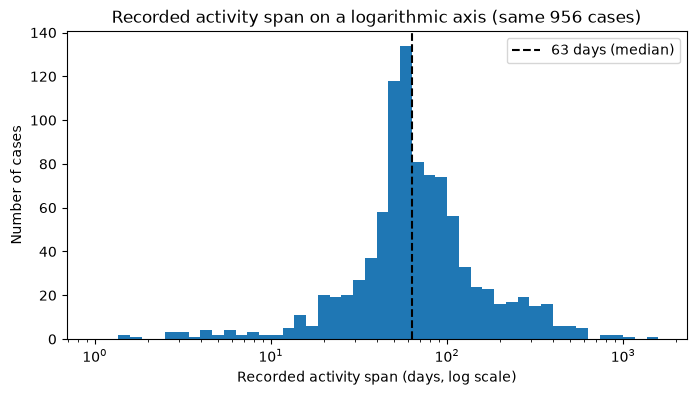

In [24]:
log_bins = [10 ** (i / 15) for i in range(49)]   # 1 to about 1,585 days, evenly spaced on a log scale

plt.figure(figsize=(8, 4))
plt.hist(ended_cases["duration_days"], bins=log_bins)
plt.xscale("log")
plt.axvline(63, color="black", linestyle="--", label="63 days (median)")
plt.title("Recorded activity span on a logarithmic axis (same 956 cases)")
plt.xlabel("Recorded activity span (days, log scale)")
plt.ylabel("Number of cases")
plt.legend()
plt.savefig(figures_folder / "eda_recorded_span_log_scale.png", dpi=120)
plt.show()

The distribution is **right-skewed**: most cases take between about one and four months, but a few take years. Those few
long cases pull the **mean (about 98 days)** above the **median (63 days)**. The median is the better description of a
typical case.

**How many cases are longer than the median of 63 days?**

In [25]:
long_cases = (ended_cases["duration_days"] > 63).sum()
print("Cases with a recorded activity span over 63 days:", long_cases, "of", len(ended_cases))

Cases with a recorded activity span over 63 days: 472 of 956


472 of the 956 cases (about half) are longer than 63 days. Section 11 explains how this becomes the modelling target.

### 8.3 Most common activities

**Count how often each English activity name occurs** and show the ten most common.

In [26]:
top_activities = df["activityNameEN"].value_counts().head(10)
top_activities

activityNameEN
send confirmation receipt                       2074
procedure change                                1752
enter senddate decision environmental permit    1397
request complete                                1267
register submission date request                1199
phase application received                      1199
forward to the competent authority              1179
regular procedure without MER                   1161
enter senddate acknowledgement                  1057
phase application receptive                      940
Name: count, dtype: int64

**Bar chart of the ten most common activities.**

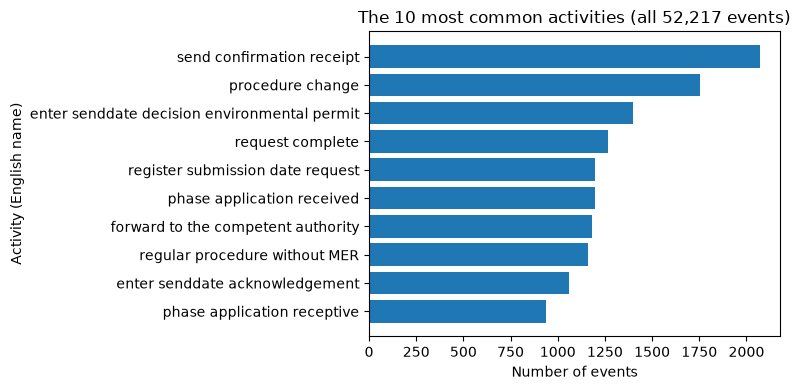

In [27]:
plt.figure(figsize=(8, 4))
plt.barh(top_activities.index[::-1], top_activities.values[::-1])
plt.title("The 10 most common activities (all 52,217 events)")
plt.xlabel("Number of events")
plt.ylabel("Activity (English name)")
plt.tight_layout()
plt.savefig(figures_folder / "eda_top_activities.png", dpi=120)
plt.show()

Some steps happen in every case: "register submission date request" occurs exactly 1,199 times. Others, such as "send
confirmation receipt" (2,074 times), can happen more than once in the same case. **Which** steps happen, and how often,
is the kind of early information the models will use.

### 8.4 Activity-code prefixes

**Group the activity codes by their prefix** (the part before the number, such as `01_HOOFD` or `02_DRZ`) and count codes
and events per prefix.

In [28]:
prefix = df["concept:name"].str.extract(r"^(\d{2}_[A-Z0-9]+)_")[0]

prefix_table = pd.DataFrame({
    "activity codes": df.groupby(prefix)["concept:name"].nunique(),
    "events": prefix.value_counts(),
}).sort_values("events", ascending=False)
prefix_table.index.name = "prefix"
prefix_table

,activity codes,events
prefix,,
01_HOOFD,146,39724
08_AWB45,37,3327
06_VD,25,1630
04_BPT,11,1251
11_AH,30,1045
09_AH,4,957
10_UOV,35,878
05_EIND,13,865
02_DRZ,12,832


The 398 activity codes belong to 20 prefixes. `01_HOOFD` contains most of the codes (146) and events (39,724). The
meaning of the prefixes is not documented, so I do not name them; the modelling notebook uses them only as groups of
related codes.

## 9. Bivariate exploration

### 9.1 Case size and recorded activity span

**Make one row per case** with three simple counts and the recorded activity span, for the same 956 cases, and calculate
their correlations.

In [29]:
case_level = df.groupby("case:concept:name").agg(
    events_per_case=("concept:name", "size"),
    unique_activities=("concept:name", "nunique"),
    unique_resources=("org:resource", "nunique"),
)
case_level = case_level.loc[ended_cases.index]
case_level["duration_days"] = ended_cases["duration_days"]
print("Cases used:", len(case_level))

correlation = case_level.corr()
correlation.round(2)

Cases used: 956


,events_per_case,unique_activities,unique_resources,duration_days
events_per_case,1.00,0.99,0.38,0.41
unique_activities,0.99,1.00,0.36,0.39
unique_resources,0.38,0.36,1.00,0.06
duration_days,0.41,0.39,0.06,1.00


**Heatmap of the correlations**, with the value written in each square.

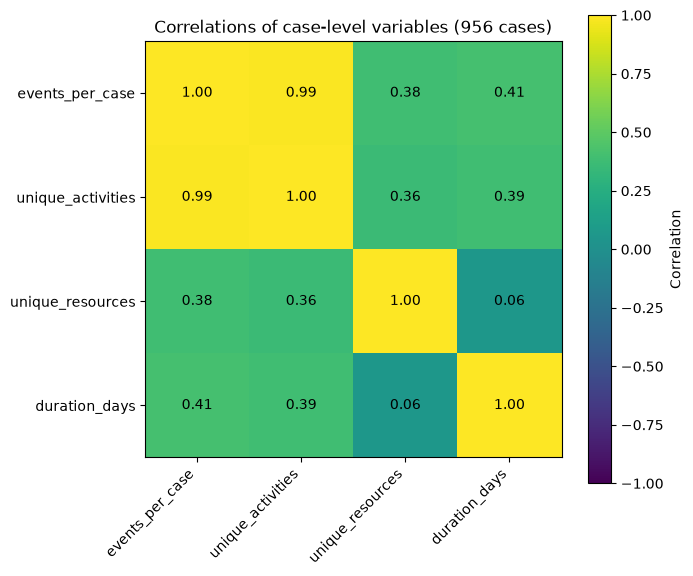

In [30]:
plt.figure(figsize=(7, 6))
plt.imshow(correlation, vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation.columns)), correlation.columns)

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center")

plt.title("Correlations of case-level variables (956 cases)")
plt.tight_layout()
plt.savefig(figures_folder / "eda_correlation_heatmap.png", dpi=120)
plt.show()

- Cases with more events also have more different activities (correlation 0.99): the two counts carry almost the same
  information.
- The recorded activity span has a moderate positive correlation with the number of events (0.41) and almost none with
  the number of resources (0.06).

Important: these counts are **whole-case recorded information**, so they are not available early, when a prediction would
be made. They show that activity is related to the span, which is why the models use activity counted **only up to an
early point in time**. Correlation does not show cause and effect.

### 9.2 Recorded end date versus last recorded event

The relationship between the two end-of-case dates was measured in section 7.5: the last recorded event came after the
recorded end date for 713 cases, before it for 170, and on it for 73. The two dates therefore do not describe the same
moment, which is why the target is based on the recorded events only.

## 10. Key findings

1. **Recorded activity spans vary enormously** (median 63 days, mean about 98, maximum 1,486), so a simple average
   describes the cases poorly and "long" cases are worth studying separately.
2. **Recorded steps are not the same as administrative completion.** The recorded end date often disagrees with the last
   recorded step, so the project predicts the recorded activity span, not a verified completion or a legal delay.
3. **Cases differ a lot** in how many steps they have (2 to 101) and in which steps occur; some steps happen in every
   case, others repeat.
4. **Activity information is related to the span.** More recorded activity goes with longer spans (correlation 0.41),
   which supports testing early activity information.
5. **The data has limits.** 45.9% of the events are at exactly local midnight and 30,433 are tied, which suggests limited
   timestamp precision and an uncertain order of tied events, and the
   243 cases without an end date are concentrated in the newest years. The four key columns are complete, and no rows
   needed to be removed.

## 11. Decisions carried forward

**Target and cohort (kept exactly as in the original research)**

- **Recorded activity span** = days from the first to the last recorded event of a case.
- **Cohort:** the 956 cases with a recorded end date (a recorded end date is not an independently verified completion).
- **Long case:** recorded activity span **more than 63 days**. 63 days is the median found in section 8. It is an
  **exploratory, data-derived** threshold, chosen while looking at all 956 cases, including the cases that later become
  test cases. It is **not** a legal or administrative deadline and it is not externally validated.

**Prediction point**

- The main modelling task uses only the events recorded in the **first 30 days** of each case. Events after day 30 must
  never be used as features.
- A case is included at day 30 only if its recorded activity span goes beyond day 30. This rule uses the last recorded
  event, which is only known afterwards, so the cohort is **retrospective**; this limitation is kept and stated in the
  modelling notebook.

**Kinds of features considered (all counted up to day 30)**

- event counts (in total and in parts of the 30 days) and days since the last event;
- activity counts and indicators (which activity codes occurred), activity groups by prefix;
- resource counts;
- repeated activities;
- an exploratory stand-in for early process progress: the highest number group of the `01_HOOFD` codes reached
  (the source-system meaning of the code prefixes is not fully documented, so this is not a verified measure of progress).

**What is not done here:** no model preprocessing or learned feature transformation is fitted here. Scaling, PCA,
TF-IDF and the choice of activity codes depend on the data, so they are fitted **only on training cases** (and again
inside every cross-validation fold) in `02_modelling.ipynb`. The exported table therefore contains the raw events only.
This notebook does calculate descriptive statistics, and the exploratory 63-day threshold, from all 956 cases with a
recorded end date, including cases that later become test cases; that limitation is stated above.

## 12. Export

**Save the event table** to `data/processed/bpic15_events.csv.gz`: a compressed CSV file that pandas can read without any
extra package. All 52,217 rows and 29 columns are saved in their original order. `index=False` leaves out the row
numbers. `"mtime": 0` leaves the save time out of the compressed file. In the tested environment, saving the same data under the
same file name gave byte-identical files; other library versions or operating systems may compress differently, so the
file checksum is only a convenience. The real proof that the data is unchanged is the round-trip check below.

In [31]:
processed_path = project_root / "data" / "processed" / "bpic15_events.csv.gz"

df.to_csv(processed_path, index=False, compression={"method": "gzip", "mtime": 0})

print("Saved:", processed_path.relative_to(project_root))
print("Size:", processed_path.stat().st_size, "bytes")
print("SHA-256:", hashlib.sha256(processed_path.read_bytes()).hexdigest())

Saved: data\processed\bpic15_events.csv.gz
Size: 1107345 bytes
SHA-256: 747ac8a518796b5dc04fcecdba1fca7d097018212cfdb3b40c1648207cf92235


**Load the file again, exactly as the modelling notebook does.** Every column is read as text first, so nothing changes
by automatic type guessing; only empty cells become missing values, and the text `EMPTY` stays a real value. Then the six
date columns are turned back into UTC dates and the fee column into a number.

In [32]:
events = pd.read_csv(processed_path, dtype="str", keep_default_na=False, na_values=[""])

date_columns = ["time:timestamp", "case:endDate", "case:startDate", "case:endDatePlanned", "dueDate", "planned"]
for column in date_columns:
    events[column] = pd.to_datetime(events[column], utc=True, format="ISO8601").astype("datetime64[us, UTC]")

events["case:SUMleges"] = events["case:SUMleges"].astype("float64")

print("Loaded:", events.shape[0], "rows,", events.shape[1], "columns")

Loaded: 52217 rows, 29 columns


**Check that nothing changed.** `assert_frame_equal` compares every value, every missing value, every data type, the
column order and the row order. If anything differed, it would stop the notebook with an error.

In [33]:
pd.testing.assert_frame_equal(events, df)
print("The reloaded table is identical to the original event table.")

The reloaded table is identical to the original event table.


The processed file reproduces the original event table exactly. It is git-ignored and re-created every time this
notebook runs (see `data/processed/README.md`), because permission to share processed copies has not been explicitly
established. `02_modelling.ipynb` loads this file in a separate session.

## 13. Appendix

### Full data dictionary with missing percentages and value counts

**Load `data/data_dictionary.csv`** and check that it describes exactly the 29 columns of the data.

In [34]:
data_dictionary = pd.read_csv(project_root / "data" / "data_dictionary.csv")

print("Columns described:", len(data_dictionary))
print("Every column of the data is described:", set(data_dictionary["Column"]) == set(df.columns))
data_dictionary[["Column", "Type / format", "Missing %", "Unique values", "Notes"]]

Columns described: 29
Every column of the data is described: True


,Column,Type / format,Missing %,Unique values,Notes
0,question,str,0.0,422,Missing answers are written as the text 'EMPTY...
1,dateFinished,str,0.0,5566,"Stored as TEXT ('YYYY-MM-DD HH:MM:SS'), not as..."
2,dueDate,"datetime64[us, UTC]",93.6,3340,Datetime (UTC); mostly missing.
3,action_code,str,0.0,397,"Equal to concept:name on every row except one,..."
4,activityNameEN,str,0.0,289,289 names; several codes share a name.
5,planned,"datetime64[us, UTC]",11.5,38879,Datetime (UTC).
6,time:timestamp,"datetime64[us, UTC]",0.0,24142,Stored in UTC. 45.9% of events are recorded at...
7,monitoringResource,str,0.0,26,Numeric identifier (no names); 26 values.
8,org:resource,str,0.0,23,Numeric identifier stored as text (no names); ...
9,activityNameNL,str,0.0,289,"Same information as activityNameEN, in Dutch."


The dictionary describes all 29 columns, and its missing percentages agree with section 7.1.